# **LIMPIEZA DE DATOS**

## **0. CARGAR LAS LIBRERÍAS NECESARIAS Y DATOS ORIGINALES**

Cargar librerias desde el entorno Colab

In [112]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

El siguiente paso es cargar datos. Podemos cargar los datos desde una URL, o "subiendolos" al entorno de ejecución

 Es el nombre que le pusimos a nuestro dataset es `df`, pero puede ser cualquier otro

In [113]:
# La base de datos puede cargarse desde una URL
df = pd.read_csv('https://github.com/estebangonzalezITM/DataScience/raw/main/datasets/diamonds.csv')
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


## **1. INSPECCIÓN Y PERFILADO**

Información inicial del DataFrame y conteo de nulos:

In [114]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB


In [115]:
df.describe()

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [116]:
# Conteno de valores nulos
df.isnull().sum()

,0
carat,0
cut,0
color,0
clarity,0
depth,0
table,0
price,0
x,0
y,0
z,0


In [117]:
print(df.duplicated().sum())

146


* Podemos graficar **histogramas** para analizar la distribución de los datos

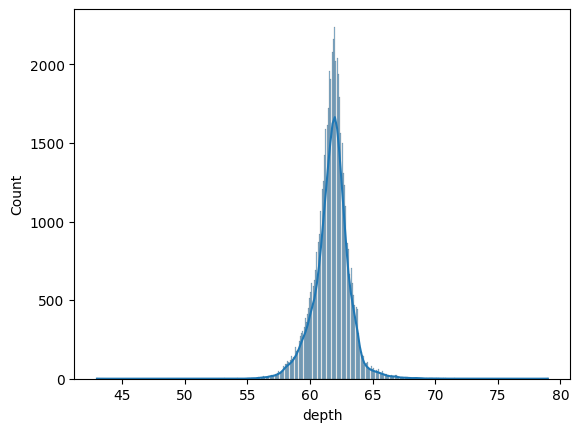

In [118]:
sns.histplot(df['depth'], kde=True)
plt.show()

<Axes: >

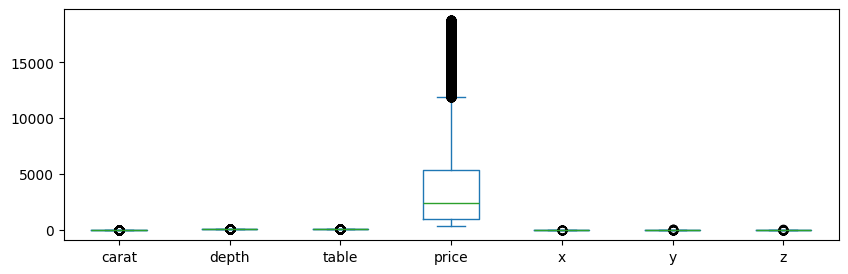

In [119]:
df.plot.box(figsize = (10,3))

<Axes: >

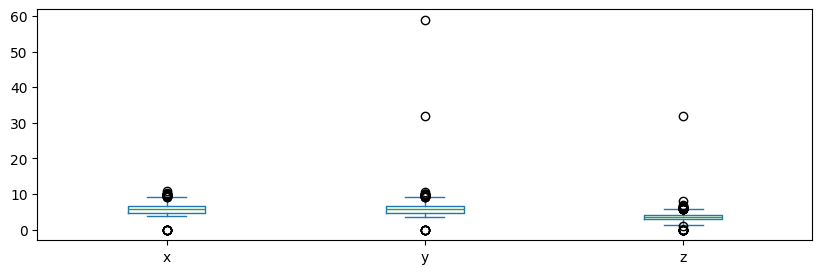

In [120]:
df[['x','y','z']].plot.box(figsize = (10,3))


<Axes: >

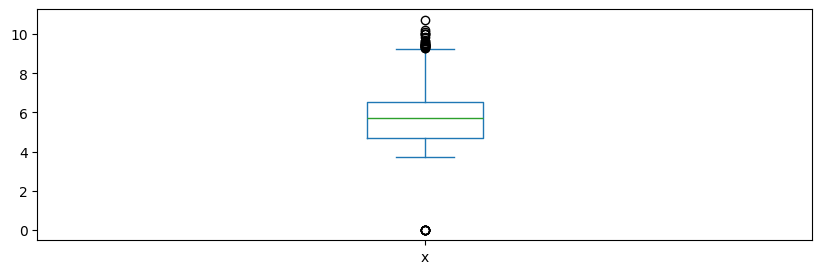

In [121]:
df['x'].plot.box(figsize = (10,3))

## **2. ELIMINACIÓN DE DUPLICADOS**

In [122]:
duplicates_before = df.duplicated().sum()                             # Esta línea cuenta las filas duplicadas tiene el dataset
if duplicates_before > 0:
    df.drop_duplicates(inplace=True)                                  # Esta línea elimina las filas duplicadas
    print(f"Se eliminaron {duplicates_before} registros duplicados.")
else:
    print("No se encontraron registros duplicados.")

Se eliminaron 146 registros duplicados.


## **3. MANEJO DE VALORES FALTANTES**

Mostramos solo las columnas con valores nulos para ser concisos

In [123]:
# Evaluamos cuáles columnas tiene datos faltantes
print("Valores nulos ANTES del manejo:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Valores nulos ANTES del manejo:
Series([], dtype: int64)


In [124]:
df

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


* En este dataset no teníamos valores faltantes, pero tenemos algundas dimensiones con valor "0", por lo que eliminamos estos datos

In [125]:
df2 = df[(df['x'] > 0)]
df2

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


In [126]:
df2 = df[(df['x'] > 0) & (df['y'] > 0) & (df['z'] > 0)]
df2

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


## **4. TRATAMIENTO DE VALORES ATÍPICOS (OUTLIERS)**

* El análisis que realizamos también mostró unas dimensiones anormalmente altas, por lo que también las filtramos

In [127]:
df2 = df2[(df2['x'] > 1.94) & (df2['x'] < 9.3) & (df2['y'] > 1.99) & (df2['y'] < 9.27) & (df2['z'] > 1.21) & (df2['z'] < 5.735)]
df2

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


In [128]:
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


**NOTA:** La columna 'Cabin' se eliminará en el siguiente paso por tener demasiados nulos.


## **5. CORRECCIÓN DE ERRORES ESTRUCTURALES**

Estandarización de formatos y categorías

**Paso 1:** Estandarización de categorías (en este caso, ya estaban limpias)

**Paso 2:** Eliminando columnas no útiles (en este caso, no es necesario)

**Paso 3:** Convirtiendo variables categóricas a numéricas.

In [129]:
df2.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


 - 'Embarked' convertida con One-Hot Encoding."

In [130]:
df2 = pd.get_dummies(df2, columns=['color'], prefix='Color')
df2 = pd.get_dummies(df2, columns=['clarity'], prefix='Cl')
df2.head()

,carat,cut,depth,table,price,x,y,z,Color_D,Color_E,...,Color_I,Color_J,Cl_I1,Cl_IF,Cl_SI1,Cl_SI2,Cl_VS1,Cl_VS2,Cl_VVS1,Cl_VVS2
0,0.23,Ideal,61.5,55.0,326,3.95,3.98,2.43,False,True,...,False,False,False,False,False,True,False,False,False,False
1,0.21,Premium,59.8,61.0,326,3.89,3.84,2.31,False,True,...,False,False,False,False,True,False,False,False,False,False
2,0.23,Good,56.9,65.0,327,4.05,4.07,2.31,False,True,...,False,False,False,False,False,False,True,False,False,False
3,0.29,Premium,62.4,58.0,334,4.20,4.23,2.63,False,False,...,True,False,False,False,False,False,False,True,False,False
4,0.31,Good,63.3,58.0,335,4.34,4.35,2.75,False,False,...,False,True,False,False,False,True,False,False,False,False


## **6. VALIDACIÓN FINAL**

Información final del DataFrame limpio:



In [131]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53736 entries, 0 to 53939
Data columns (total 23 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53736 non-null  float64
 1   cut      53736 non-null  object 
 2   depth    53736 non-null  float64
 3   table    53736 non-null  float64
 4   price    53736 non-null  int64  
 5   x        53736 non-null  float64
 6   y        53736 non-null  float64
 7   z        53736 non-null  float64
 8   Color_D  53736 non-null  bool   
 9   Color_E  53736 non-null  bool   
 10  Color_F  53736 non-null  bool   
 11  Color_G  53736 non-null  bool   
 12  Color_H  53736 non-null  bool   
 13  Color_I  53736 non-null  bool   
 14  Color_J  53736 non-null  bool   
 15  Cl_I1    53736 non-null  bool   
 16  Cl_IF    53736 non-null  bool   
 17  Cl_SI1   53736 non-null  bool   
 18  Cl_SI2   53736 non-null  bool   
 19  Cl_VS1   53736 non-null  bool   
 20  Cl_VS2   53736 non-null  bool   
 21  Cl_VVS1  53736 no

In [132]:
df2.head()

,carat,cut,depth,table,price,x,y,z,Color_D,Color_E,...,Color_I,Color_J,Cl_I1,Cl_IF,Cl_SI1,Cl_SI2,Cl_VS1,Cl_VS2,Cl_VVS1,Cl_VVS2
0,0.23,Ideal,61.5,55.0,326,3.95,3.98,2.43,False,True,...,False,False,False,False,False,True,False,False,False,False
1,0.21,Premium,59.8,61.0,326,3.89,3.84,2.31,False,True,...,False,False,False,False,True,False,False,False,False,False
2,0.23,Good,56.9,65.0,327,4.05,4.07,2.31,False,True,...,False,False,False,False,False,False,True,False,False,False
3,0.29,Premium,62.4,58.0,334,4.20,4.23,2.63,False,False,...,True,False,False,False,False,False,False,True,False,False
4,0.31,Good,63.3,58.0,335,4.34,4.35,2.75,False,False,...,False,True,False,False,False,True,False,False,False,False


In [133]:
df2.isnull().sum()

,0
carat,0
cut,0
depth,0
table,0
price,0
x,0
y,0
z,0
Color_D,0
Color_E,0


## **Guardar el resultado en un nuevo archivo**

In [134]:
df2.to_csv('df_cleaned.csv', index=False)

Ver la distribución final de los datos

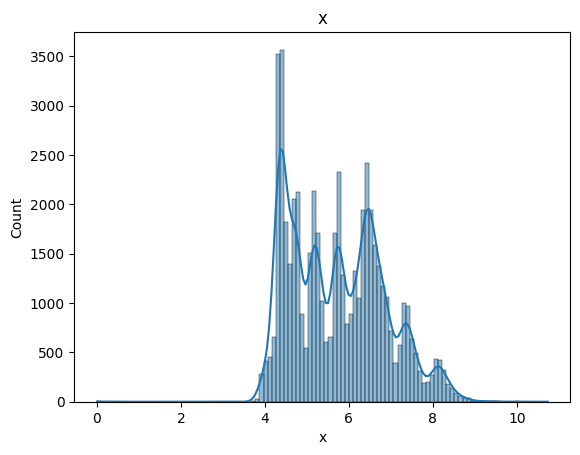

In [73]:
sns.histplot(df['x'], kde=True)
plt.title('x')
plt.show()

In [101]:
df2.head()

,carat,cut,depth,table,price,x,y,z,Color_D,Color_E,...,Color_I,Color_J,Cl_I1,Cl_IF,Cl_SI1,Cl_SI2,Cl_VS1,Cl_VS2,Cl_VVS1,Cl_VVS2
0,0.23,Ideal,61.5,55.0,326,3.95,3.98,2.43,False,True,...,False,False,False,False,False,True,False,False,False,False
1,0.21,Premium,59.8,61.0,326,3.89,3.84,2.31,False,True,...,False,False,False,False,True,False,False,False,False,False
2,0.23,Good,56.9,65.0,327,4.05,4.07,2.31,False,True,...,False,False,False,False,False,False,True,False,False,False
3,0.29,Premium,62.4,58.0,334,4.20,4.23,2.63,False,False,...,True,False,False,False,False,False,False,True,False,False
4,0.31,Good,63.3,58.0,335,4.34,4.35,2.75,False,False,...,False,True,False,False,False,True,False,False,False,False


In [97]:
df2.columns

Index(['carat', 'cut', 'depth', 'table', 'price', 'x', 'y', 'z', 'Color_D',
       'Color_E', 'Color_F', 'Color_G', 'Color_H', 'Color_I', 'Color_J',
       'Cl_I1', 'Cl_IF', 'Cl_SI1', 'Cl_SI2', 'Cl_VS1', 'Cl_VS2', 'Cl_VVS1',
       'Cl_VVS2'],
      dtype='object')

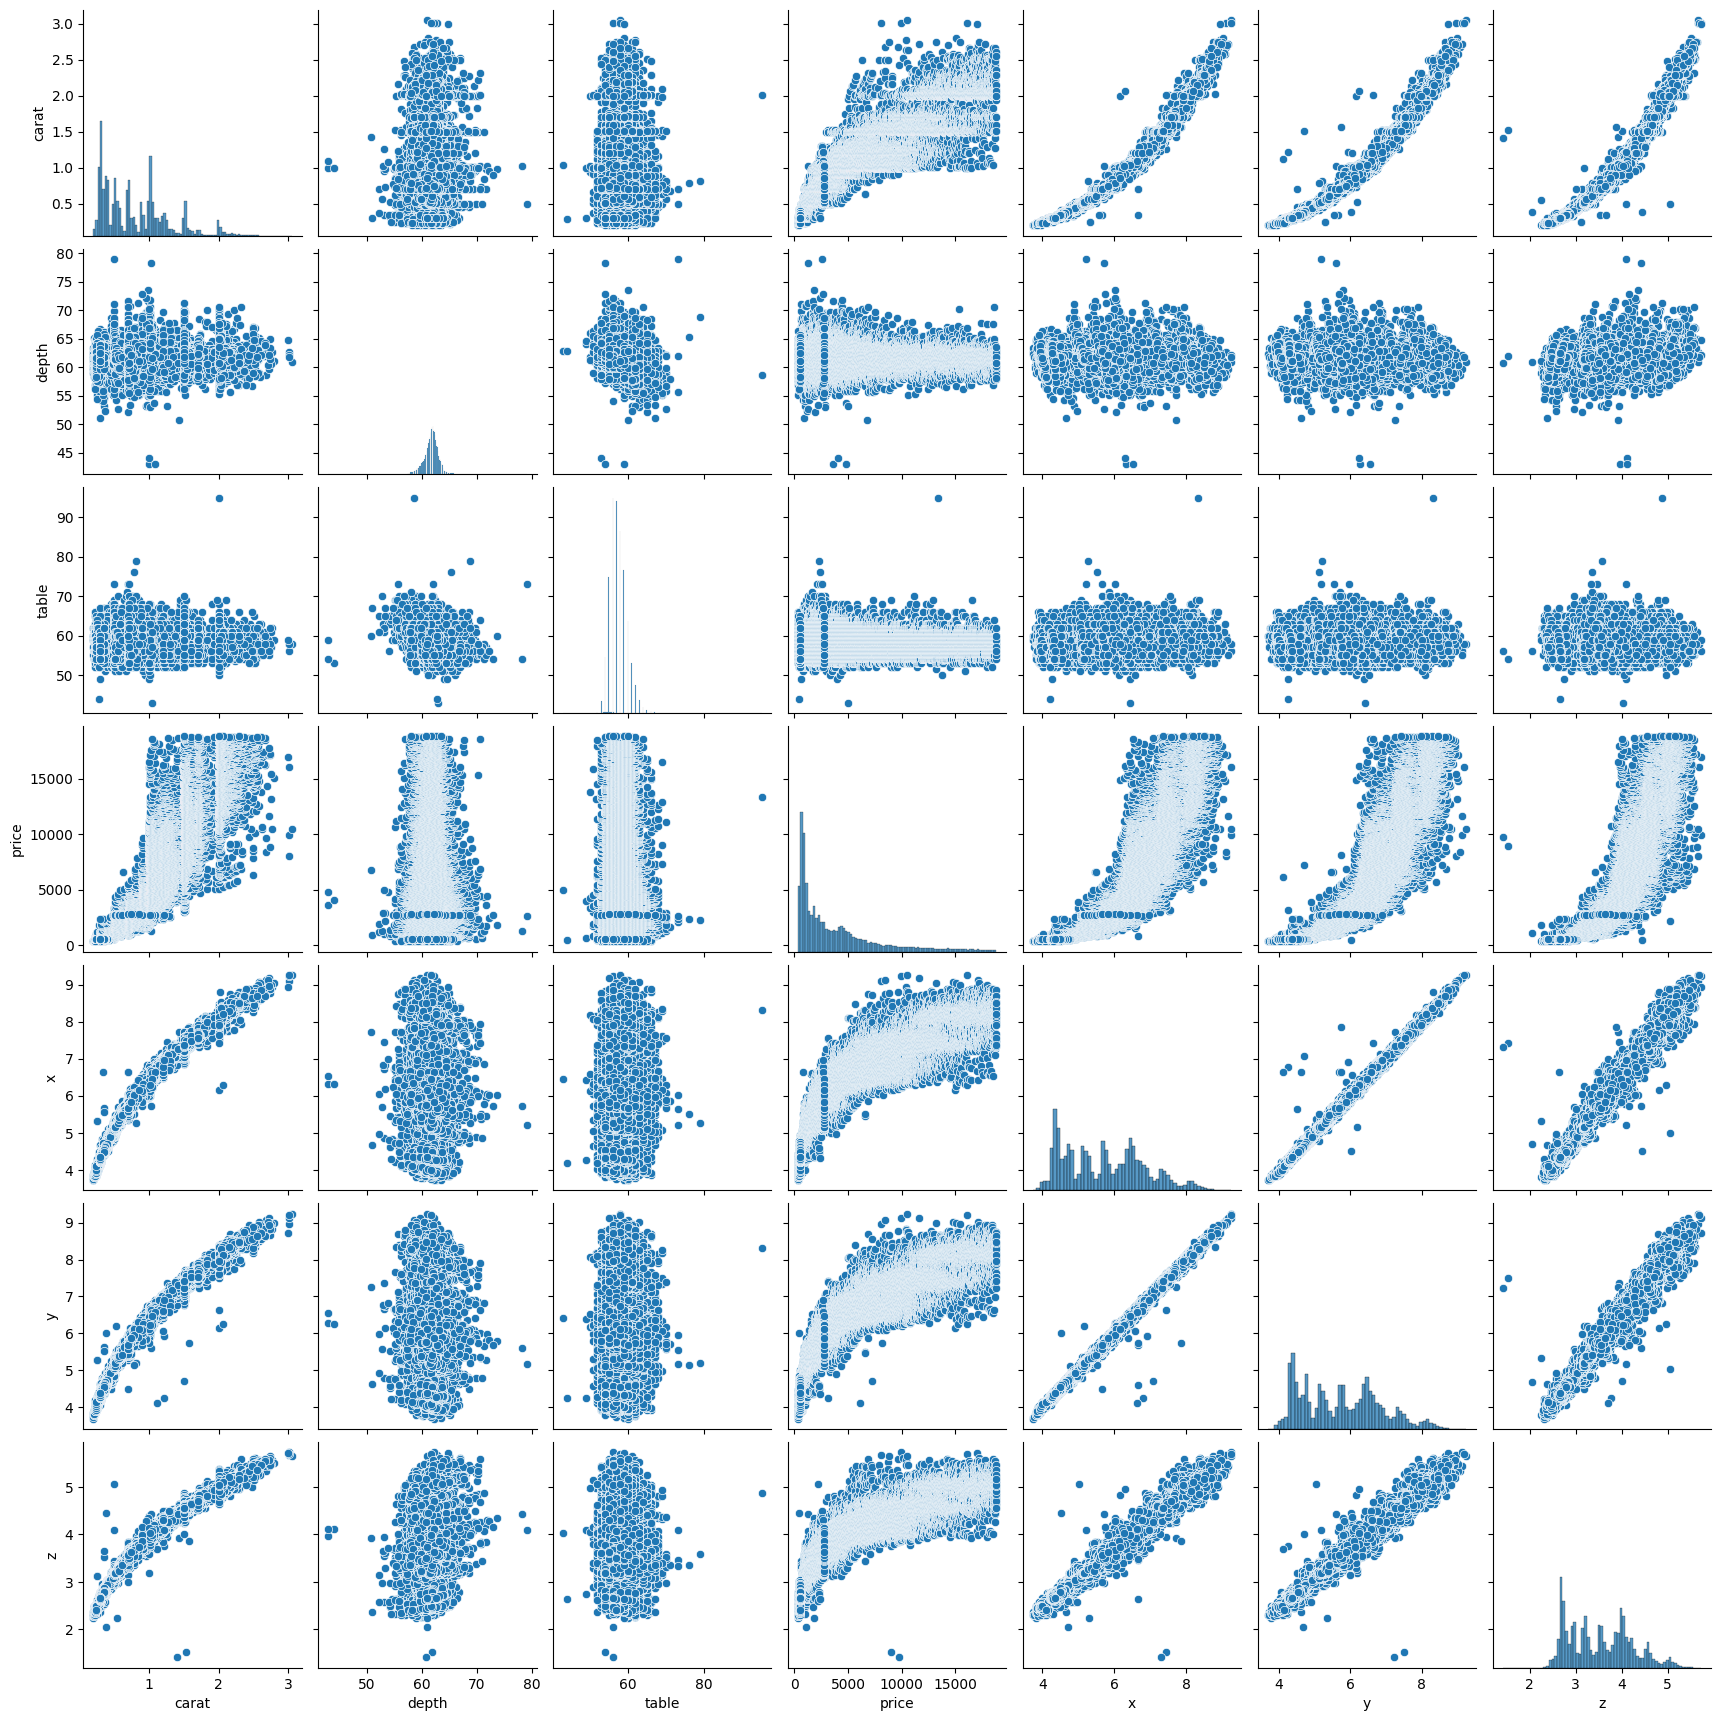

In [102]:
sns.pairplot(df2[['carat','depth', 'table', 'price','x', 'y', 'z']])
plt.show()

[]

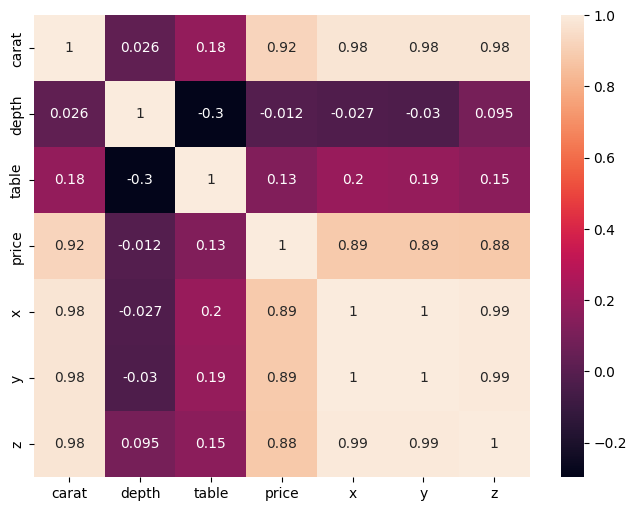

In [109]:
plt.figure(figsize=(8,6))
sns.heatmap(df2[['carat','depth', 'table', 'price','x', 'y', 'z']].corr(), annot=True )  # , cmap='turbo'
plt.plot()

In [106]:
from matplotlib import colormaps
print(list(colormaps))

['magma', 'inferno', 'plasma', 'viridis', 'cividis', 'twilight', 'twilight_shifted', 'turbo', 'berlin', 'managua', 'vanimo', 'Blues', 'BrBG', 'BuGn', 'BuPu', 'CMRmap', 'GnBu', 'Greens', 'Greys', 'OrRd', 'Oranges', 'PRGn', 'PiYG', 'PuBu', 'PuBuGn', 'PuOr', 'PuRd', 'Purples', 'RdBu', 'RdGy', 'RdPu', 'RdYlBu', 'RdYlGn', 'Reds', 'Spectral', 'Wistia', 'YlGn', 'YlGnBu', 'YlOrBr', 'YlOrRd', 'afmhot', 'autumn', 'binary', 'bone', 'brg', 'bwr', 'cool', 'coolwarm', 'copper', 'cubehelix', 'flag', 'gist_earth', 'gist_gray', 'gist_heat', 'gist_ncar', 'gist_rainbow', 'gist_stern', 'gist_yarg', 'gnuplot', 'gnuplot2', 'gray', 'hot', 'hsv', 'jet', 'nipy_spectral', 'ocean', 'pink', 'prism', 'rainbow', 'seismic', 'spring', 'summer', 'terrain', 'winter', 'Accent', 'Dark2', 'Paired', 'Pastel1', 'Pastel2', 'Set1', 'Set2', 'Set3', 'tab10', 'tab20', 'tab20b', 'tab20c', 'grey', 'gist_grey', 'gist_yerg', 'Grays', 'magma_r', 'inferno_r', 'plasma_r', 'viridis_r', 'cividis_r', 'twilight_r', 'twilight_shifted_r', 't